# Project 1: Efficient waveform coding for data transmission using auto-regressive models

### Please first fill in your names and group number

Group number: 11

member names: Sen Huybrechts, Daan Debaillie

In [1]:
# Define notebook style and latex commands

from importstatements import notebook_styling
notebook_styling()

%matplotlib inline

<IPython.core.display.Latex object>

# Goal of this project

In this project, we will explore the use of auto-regressive models (AR models, topic 2) to efficiently encode a speech signal. We will look at stationary and adaptive coding. The purpose of the project is to further solidify concepts learnt in the course and to adapt them to the processing of non-stationary signals. Additionally, the development of adaptive models forms a good introduction to the topic of adaptive signal processing towards the end of the course. 

# Submitting the project

The deliverable for the project should only consist of this notebook and possibly some extra `.py` files if wanted. Meaning that this notebook contains both your code and your answers to the questions (with figures and tables).
The code/answer locations will be indicated; however, it is allowed to add extra cells.

The project should be uploaded in the form of a zip- or a rar-archive onto the drop box of the course. **Make sure the contents are readable to all the course evaluators and not just the lecturer-in-charge.**

Make sure your Python code is well-commented. Also, make sure that the axes of the figures are clearly labelled, and that the figures have titles. **You will get points for doing so!** Keep your answers compact but clear. You may write the answers in Dutch or English.

# Conventions and notations

The following are the conventions and notations which shall be consistently used throughout the project.
1. The development will be on signals sampled at $\fsamp=16\unit{kHz}$. The files provided for the development and testing are also at this sampling rate. 
2. The samples of the input signal can span the full interval $[-1,1]$ and are sampled with high precision (bit-depth).

# Setting

*Teleximus* wants to send sound over a channel, e.g. a phone call. However, with the rising energy prices, *Teleximus* wants to limit the bandwidth as much as possible in order to save costs. You are responsible for designing, implement and fine-tuning a system where the audio at the receiver is still of sufficient quality. Your system is designed under the assumption of a lossless channel, and will look like this:

<figure id="fig:schematic_ende_coding">

![x(n) goes through the model, C, D and through model and becomes xhat](assets/figs/schematic_waveform_encoding_decoding.png "General schematic for waveform encoding and decoding")
<!-- <img src="assets/figs/schematic_waveform_encoding_decoding.png" title="Tooltip" caption="This caption doesn't work" /> -->
<figcaption style="clear: left;margin: .75em 0;text-align: center;font-style: italic;line-height: 1.5em;">
General schematic for waveform encoding and decoding</figcaption>
</figure>

Where $x(n)$ is the signal you want to send, C and D are the (en)coder en decoder, respectively, and the model (both at the encoder and decoder side) is the processing you do in order to get the best possible signal quality at the decoder $\hat{x}(n)$. $q_r(n)$ is a sequence of binary codes that *approximates* the signal waveform $r(n)$

*Note: this schematic can, next to more efficiently transmitting data, also be used to more efficiently save and load data, for e.g. playback of music.*

You remember that the **auto-regressive model** can, based on the previous samples, predict the subsequent sample. If both the encoder and decoder have access to the same AR-model, you only need to encode the *prediction error*, which should be much smaller compared to the full signal if the AR-model is well-tuned. To tune the AR-model, you can use the statistics of generic speech data. However, the model can also be adapted to the current statistics of the signal. Therefore, you also want to investigate *adaptive* AR-models.

Your team comes up with the following **game-plan**:

<ol style="list-style-type:upper-alpha">
   <li>Implement a quality measure that can give an indication of how good your encodings work. <b>segmental SNR</b> (signal to (quantisation) noise ratio) will be used for this.</li>
  <li>Evaluate the effect of quantisation on the quality of the audio. For that, three different quantisers are proposed. This type of coding is called <b>PCM</b> (pulse-code modulation).</li>
  <li>Implement and evaluate the <b>AR-model.</b></li>
  <li>Integrate the AR-model in the encoding. This type of coding is called <b>DPCM</b> (differential PCM).</li>
  <li>Try to improve the AR-model by making it adaptive, which will be termed <b>APC</b> (adaptive predictive encoding). </li>
  <li><b>Compare</b> all methods. </li>
</ol> 

Further, to verify the correctness of the implementation and evaluate the methods, the following **development and evaluation process** will be used:

<ol>
  <li><b>Behaviour of the system:</b> to test if the system works as expected, we will use a predictable periodic signal, which is a combination of multiple sine waves (given by us). The predictability might also show some of the behaviour and advantages or disadvantages of the methods.</li>
  <li><b>Development Phase:</b> During this phase, you will use a development speech signal to optimise the free parameters of the system (like how many bits are needed in the quantiser, or how many previous samples the AR-model has access to, in order to predict the next sample). These free parameters represent a  trade-off between signal quality and the information flow rate (needed bandwidth). <i>Your explanation for the choice is much more important than the actual choice</i></li>
  <li><b>Evaluation Phase:</b> once the free parameters are locked in, you will test the methods based on an independent test file. The methods are not fully optimised on this independent test, just like the speech files that will be processed by the encoder in practice. So, if the system performs well on this file, we may generally expect it to perform well in actual practice. The results on the test file are thus used to compare the different methods (e.g. stationary vs adaptive coding) </li>
</ol>

<div style = "font-size:22px"><u> Accessing, saving and listening to the audio signals </u></div>

To access the signals, run the underlying cell. The signals are already scaled to be in the correct range. For convenience, we repeated how to save the audio files to the results folder and listen to the audio files from the introduction notebook.

In [2]:
import importstatements # also import the namespace itself, not only all functions
from importstatements import getSpeechFragment, setSpeechFragment
from importstatements import * #also import the imports from there

# Global parameters
Fs = int(16E3) # Hz - sampling freq
wav_periodic = 'assets/audio/periodic_signal.wav'
wav_develop = 'assets/audio/develop.wav'
wav_test = 'assets/audio/test.wav'
importstatements.audiofolder = 'assets/audio/results/'
importstatements.Fs = Fs

In [3]:
# get signals

periodic_signal = getSpeechFragment(wav_periodic)
develop_signal = getSpeechFragment(wav_develop)
test_signal = getSpeechFragment(wav_test)

In [4]:
# save a audio file to the results folder

setSpeechFragment('periodic_signal', periodic_signal)

Write to assets/audio/results/periodic_signal.wav with sampling freq = 16000 Hz


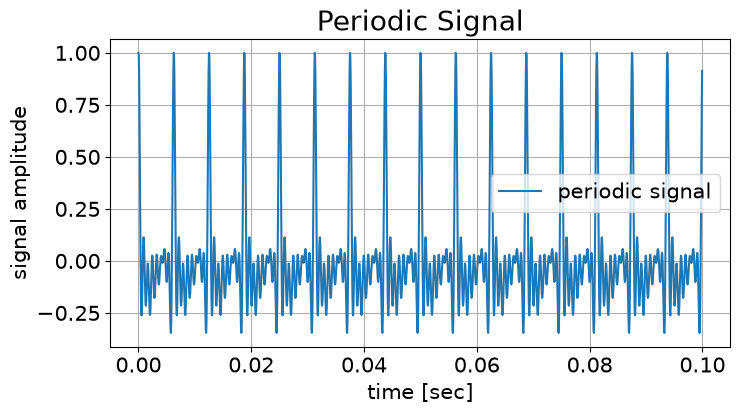

In [5]:
# plot periodic signal

plt.rc('font', size=10) # controls default text sizes
plt.rc('axes', titlesize=20) # fontsize of the axes title
plt.rc('axes', labelsize=15) # fontsize of the x and y labels
plt.rc('xtick', labelsize=15) # fontsize of the tick labels
plt.rc('ytick', labelsize=15) # fontsize of the tick labels
plt.rc('legend', fontsize=15) # legend fontsize
plt.rc('figure', titlesize=35) # fontsize of the figure title

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot()
t = np.arange(len(periodic_signal))/Fs 
ax.plot(t, periodic_signal, label='periodic signal')

ax.set_xlabel('time [sec]') # add x-axis label
ax.set_ylabel('signal amplitude') # add y-axis label
ax.grid(True) # show grid lines 
ax.legend() # add legend
ax.set_title('Periodic Signal');
# ax.set_ylim(-1.05,1.05);

In [6]:
# listen to the audio file

print('#########################')
print('development signal')
ipd.display(ipd.Audio(develop_signal, rate=Fs))
print('test signal')
ipd.display(ipd.Audio(test_signal, rate=Fs))

#########################
development signal


test signal


<div class="step">A. segmental SNR</div>

You will have to evaluate different methods, each with a lot of tunable free parameters. Therefore, we often use representative instrumental quality metrics that can be quickly and easily computed. One such metric computes the signal quality by comparing the energy error signal $d(n) = x(n) - \hat{x}(n)$ to the original source signal $x(n)$. In theory, the signal to noise ratio (SNR) metric, developed for additive noise, can be used for this:

$$
SNR = 10 \: \log_{10} \frac{E_{x}}{E_{d}}
$$

with $E_{x}$ the energy of $x$ and $E_{d}$ the energy of $d$

<div class="alert alert-quiz">
    
You can take the short quiz on SNR on Ufora
</div> 

However, in practice, this metric is very sensitive to the silence regions in the signal. Therefore, we choose an alternative measure termed the *segmental* SNR. The segmental SNR is based on computations of the SNR over *segments of the signal where the regions of silence are excluded*. Consider such a signal segment $\idxa$, where the source signal is given by $x_k(n)$ and the error signal by $d_k(n)$. Let $E_{xk}$ and $E_{dk}$ represent the energies of the respective signals for this segment. Then, the segmental SNR is defined as follows:
$$
SNR_{seg} = 10 \: \log_{10} \left(\frac{ \sum_k \: S_k \: \frac{E_{xk}}{E_{dk}} }
                                 { \sum_k S_k } \right),
                                 \hspace{10mm} S_k \in \{0,1\}
$$

Where $S_k$ is a flag that indicates whether a segment is a silence region or not. To define this, we will set

$$
S_k =
    \begin{cases}
      1 & E_{xk} > 0.01 \max_k E_{xk} \\
      0 & \text{otherwise}
    \end{cases}
$$

This means that only signal segments that have an energy of at least 1\% of the maximum energy segment contribute to the SNR metric. 

Assume $L$ samples per segment. Note that the last segment is not complete if the number of samples in $\tds{x}$ is not an integer multiple of $L$. What would be a good method to handle this?

But speech quality is a perceptual phenomenon that cannot be measured in a straightforward manner. It is therefore important **to also listen to the audio fragments** to verify conclusions drawn based on the segmental SNR. This may reveal differences that the SNR metric cannot capture, as it does not take into account how we perceive sound.

<div class="alert alert-info">
    
Develop a function `SNR = estimate_seg_SNR(x, xhat, L)` that computes the segmental SNR on segments of length $L$ samples. It is very likely that the signal is not a perfect multiple of $L$. You can either truncate the signals or zero pad them to solve this problem.
</div>

In [7]:
def estimate_seg_SNR(x, xhat, L=320):
    if (len(x) != len(xhat)):      # x and xhat have the same length
        print("X and xhat must have the same length")
        return np.nan
    if (not np.any(x)):
        print("Signal is 0, SNR_seg is undefined")  # signal only consists of zeros
        return np.nan

    if (L > len(x)):
        L = len(x)
    aantal_segmenten = len(x) // L


    x_accent = x[:L * aantal_segmenten]  
    xhat_accent = xhat[:L * aantal_segmenten]     # adjust the size of x and xhat

    d = x_accent - xhat_accent         # compute the error signal d

    E_xk = np.zeros(aantal_segmenten)    
    E_dk = np.zeros(aantal_segmenten)     # make arrays of the right size for E_xk and E_dk

    for i in range(aantal_segmenten):
        E_xk[i] = np.sum(x_accent[i*L:(i+1)*L]**2)
        E_dk[i] = np.sum(d[i*L:(i+1)*L]**2)      # compute the energies of the signal x and of the error signal d 
    max_E_xk = np.max(E_xk)     # find the maximum energy out of all segment-energies

    E_dk[E_dk == 0] = 1E-30      # if the error-segment-energy is 0 --> give it a very small value (so that we don't divide by 0)
    S_k = np.where(E_xk > 0.01 * max_E_xk, 1, 0)   # compute the S_k flag (normally it wont be the zero array, because max_E_xk is always greater than 0.01 * max_E_xk exept where the signal is 0 but we have already handled this)

    
    # SNR = 10 * np.log10(np.sum(np.minimum(S_k * E_xk / E_dk, 100)) / np.sum(S_k))   # compute the SNR_seg

    SNR = 10 * np.log10(np.sum(np.minimum(S_k * E_xk / E_dk, 1000000000000)) / np.sum(S_k))   # compute the SNR_seg

    # !!! if x and xhat are identical then E_xk / E_dk would be huge, to fix this (and so that we get a right value in the last test) we have limited each segment contribution to the sum to 100
    

    return np.round(SNR, 5)

In [8]:
# def estimate_seg_SNR(x, xhat, L=320):
#     if np.count_nonzero(x) == 0: return "geen aangelegd signaal" # Check if signal x is nonzero

#     if L > len(x): L = len(x) # Make sure L is not too large
#     Segments_count = len(x) // L
#     x, xhat = np.asarray(x)[:Segments_count * L].reshape(Segments_count, L), np.asarray(xhat)[:Segments_count * L].reshape(Segments_count, L) # Trunkate x and xhat and put them in matrices
    
#     Exk = np.sum(np.abs(x) ** 2, axis = 1)
#     Edk = np.sum(np.abs(x - xhat) ** 2, axis = 1) + 1E-30  # Avoid division by zero for edge-case where of perfect reconstruction within a segment
#     Sk = np.where(Exk > 0.01*max(Exk), 1, 0)

#     # print(Exk)
#     # print("\n\n\n")
#     # print(Edk)
#     # print("\n\n\n")
#     # return 10 * np.log10(np.sum(np.minimum(Sk * Exk/Edk, 10000)) / np.count_nonzero(Sk)) # If Edk is small => Exk/Edk is large, so take the minimum of Exk/Edk and 100 to avoid large SNR in case of perfect reconstruction in one or more segments
#     return 10 * np.log10(np.sum(np.minimum(Sk * Exk/Edk, 100000000000)) / np.count_nonzero(Sk)) # If Edk is small => Exk/Edk is large, so take the minimum of Exk/Edk and 100 to avoid large SNR in case of perfect reconstruction in one or more segments

<div class="alert alert-info">

Now test your function by generating the signals from which you can calculate/know the SNR yourself.

</div>

In [9]:
# test seg_SNR
# VALUES FROM THE QUIZ
print(estimate_seg_SNR(np.ones(100), 2*np.ones(100), L=20)) # x -> 1s, xhat -> 2s ==> SNR 0dB

print(estimate_seg_SNR(np.ones(200), np.zeros(200), L=10)) # x -> 1s, xhat -> 0s ==> SNR = 0dB

print(estimate_seg_SNR(np.ones(500), 1.1*np.ones(500), L=2)) # x -> 1s, xhat -> 1.1s ==> SNR = 20dB

0.0
0.0
20.0


<div class="alert alert-info">

Also, test your function in case there is silence in the signal $x(n)$.

</div>

In [10]:
# test seg_SNR
print(estimate_seg_SNR(np.zeros(100), np.zeros(100), L = 10) , "\n\n") # signal consists of only 0s

x = np.ones(1000)              # signal where exactly 2 segments are 0 in x and xhat ==> SNR = 20 dB
x[100: 301] = 0
xhat = 1.1*np.ones(1000)
xhat[100:301] = 0
print(estimate_seg_SNR(x, xhat, L = 100))

x = np.ones(1000)    # signal where some segments of x are 0, some segments should be excluded (S_k = 0)
x[85:275] = 0
xhat = 1.1*np.ones(1000)
print(estimate_seg_SNR(x, xhat, L=50))

Signal is 0, SNR_seg is undefined
nan 


20.0
19.46427


<div class="alert alert-info">

Note that there is one more edge case that is currently not mentioned yet. Try to come up with this edge case yourself, handle it in the `estimate_seg_SNR` function and test if it is now handled.

*Hint*: What happens when a quantiser can perfectly match the original signal for one or more segments?
</div>

In [11]:
# test seg_SNR
x = np.ones(1000)
xhat = np.ones(1000)        # make x and xhat identical

print(estimate_seg_SNR(x, xhat, L=50))


x = np.ones(1000)
xhat = 1.1*np.ones(1000)        # make x and xhat identical
xhat[84: 307] = 1

print(estimate_seg_SNR(x, xhat, L=50))

120.0
113.0103


Since you will use this function quite a bit, we also provide an additional check. The results should be very close to 20dB (depending on your specific implementation, it can differ a bit due to e.g. precision).

In [12]:
# check: should be very close to 20dB

snr_test_x = np.load('./assets/test_signals/snr_test_x.npy')
snr_test_x_hat = np.load('./assets/test_signals/snr_test_x_hat.npy')
print(estimate_seg_SNR(snr_test_x, snr_test_x_hat))

109.78811


<div class="alert alert-info">

Describe what you did to validate the correct implementation of the segmental SNR function

</div>

<div class="alert alert-success">
To validate the implementation, we made a few signals and tested the estimate_seg_SNR-function.
First we used the signals from the quiz and made sure we got the correct output.
Secondly, we made the signal zero and looked at the output. As well as the output of a signal with some segments made zero.
Lastly, we made a signal that exactly matched the estimated signal and validated the output, as well as a signal that only matched in some segments. 
We also made sure the given check was correct.
    
Over multiple iterations we corrected the function-implementation.
We made sure that in places were 0-division could occur, that the 0s were replaced by small numbers. We also made sure that each segment could only contribute for a given amount, because if two segments were identical they would contribute too much to the SNR.
</div>

<div class="step">B. PCM</div>
<br>
<div class="sup-step">B.1 Quantisers</div>

The following figure depicts a compact representation of a quantiser.

<figure id="fig:quantiser">

![schema - alt text](assets/figs/quantiser.png "quantiser schematic")
<figcaption style="clear: left;margin: .75em 0;text-align: center;font-style: italic;line-height: 1.5em;">
Schematic of a quantiser</figcaption>
</figure>

The notation $Q_{B,R}$ indicates that each quantiser possesses two **free parameters**:
1. the *scale factor* $R$ indicates how large $|\hat{r}(n)|$ can be.
2. the *word length* $\mathcal{B}$, which is the number of bits per sample to represent the waveform $q_r(n)$

Let's compare three different methods to quantise $\tds{r}$. To implement the quantisers, these numpy functions might be useful: [`np.floor`][floor], [`np.clip`][clip], [`np.around`][around], [`np.abs`][abs] and [`np.sign`][sign].

##### Quantiser1
The first quantiser quantises $r(n)$ according to:
\begin{align}
q_r(n)     & = \fcn{floor}\biggsb{\frac{r(n)}{R} \: 2^{\mathcal{B}-1}} \label{eq:quant1a} \tag{1}\\
q_r(n)     & = \fcn{limit}\bigsb{q_r(n), \mathcal{B}} \label{eq:quant1b} \tag{2}\\
\hat{r}(n) & = \bignp{q_r(n) + 0.5}\, \dfrac{R}{2^{\mathcal{B}-1}} \label{eq:quant1c} \tag{3}
\end{align}
Here, the signal is first clipped to integer values and then limited so that $q_r(n)$ has an integer value in the interval $[-2^{\mathcal{B}-1}, 2^{\mathcal{B}-1}-1]$ (since this is the largest interval that can be represented using $\mathcal{B}$ bits). For our case, the scale $R$ is never greater than 1 and is fixed based on the range of signal values in the development file.

##### Quantiser2 
This quantiser has the following characteristics:
\begin{align}
q_r(n)     & = \fcn{round}\biggsb{\dfrac{r(n)}{R} \: 2^{\mathcal{\mathcal{B}}-1}} \label{eq:quant2a} \tag{4}\\
q_r(n)     & = \fcn{limit}\bigsb{q_r(n), \mathcal{\mathcal{B}}} \label{eq:quant2b} \tag{5} \\
\hat{r}(n) & = q_r(n) \: \dfrac{R}{2^{\mathcal{\mathcal{B}}-1}} \label{eq:quant2c} \tag{6}
\end{align}

##### Quantiser3
This quantiser quantises $\tds{r}$ as follows:
\begin{align}
q_r(n)     & =  \fcn{floor}\biggsb{\fcn{sign}(r(n)) \: \left(\frac{|r(n)|}{R}\right)^{\frac{1}{4}} \: 2^{\mathcal{B}-1}} \label{eq:quant3a} \tag{7}\\
q_r(n)     & =  \fcn{limit}\bigsb{q_r(n), \mathcal{B}} \label{eq:quant3b} \tag{8}\\
\hat{r}(n) & =  \fcn{sign}(q_r(n)) \left| \frac{q_r(n) + 0.5}{2^{\mathcal{B}-1}} \right|^4 \: R \label{eq:quant3c} \tag{9}
\end{align}
 
[floor]: https://numpy.org/doc/stable/reference/generated/numpy.floor.html
[clip]: https://numpy.org/doc/stable/reference/generated/numpy.clip.html
[around]: https://numpy.org/doc/stable/reference/generated/numpy.around.html
[abs]: https://numpy.org/doc/stable/reference/generated/numpy.absolute.html
[sign]: https://numpy.org/doc/stable/reference/generated/numpy.sign.html


<div class="alert alert-info">
    
Develop functions `rhat = quantise<1...3>(r, B, R)` that quantise a signal `r` to `rhat` using a scale $R$ and a code length of $\mathcal{B}$ bits per sample.
    
</div>

In [13]:
def quantise1(r, B=4, R=1):          # implementation of the first quantiser (formula 1 .. 3)
    
    q_r = np.floor(r / R * 2**(B-1))
    q_r = np.clip(q_r, -2**(B-1), 2**(B-1)-1)

    rhat = (q_r + 0.5) * R / (2**(B-1))
    
    return rhat

def quantise2(r, B=4, R=1):         # implementation of the second quantiser (formula 4 .. 6)
    
    q_r = np.around(r / R * 2**(B-1))
    q_r = np.clip(q_r, -2**(B-1), 2**(B-1)-1)

    rhat = q_r * R / (2**(B-1))
    
    return rhat

def quantise3(r, B=4, R=1):         # implementation of the third quantiser (formula 7 .. 9)

    q_r = np.floor(np.sign(r) * ((np.abs(r) / R)**(1/4)) * 2**(B-1))
    q_r = np.clip(q_r, -2**(B-1), 2**(B-1)-1)

    rhat = np.sign(q_r) * np.abs((q_r + 0.5) / (2**(B-1)))**4 * R
    
    return rhat

<div class="alert alert-info">
    
Plot the input vs output characteristics for the three quantisers, assuming the input is a **linearly** increasing signal from $[-1,1]$. Possible helpful numpy functions are: [`np.linspace`][linspace] or [`np.arange`][arange]. Please look carefully at what happens at the start en endpoint of the generated array. Take $\mathcal{B} = 4$ and $R = 1$?
    
</div>

[arange]: https://numpy.org/doc/stable/reference/generated/numpy.arange.html
[linspace]: https://numpy.org/doc/stable/reference/generated/numpy.linspace.html#numpy.linspace


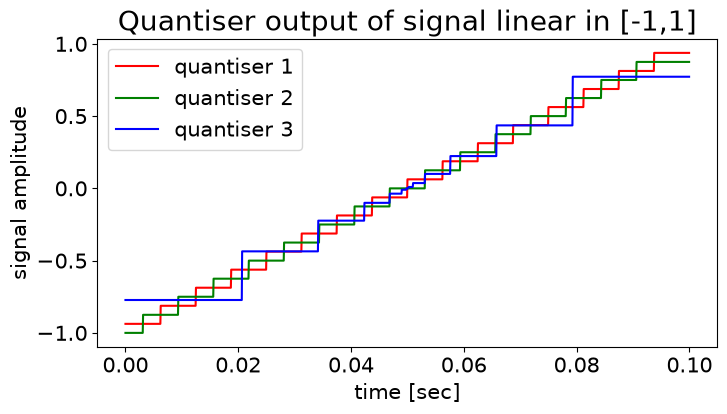

In [14]:
# plot quantisers on linear intput signal with B=4, R=1
input_signal = np.linspace(-1, 1, num=len(t))          # generate lineair signal

quantiser_1_lin = quantise1(input_signal, B=4, R=1)    # quantise1 the lineair signal
quantiser_2_lin = quantise2(input_signal, B=4, R=1)    # quantise2 the lineair signal
quantiser_3_lin = quantise3(input_signal, B=4, R=1)    # quantise3 the lineair signal

plt.figure(figsize=(8,4))
plt.title('Quantiser output of signal linear in [-1,1]')
plt.xlabel('time [sec]')
plt.ylabel('signal amplitude')
plt.plot(t, quantiser_1_lin, color='r', label='quantiser 1')
plt.plot(t, quantiser_2_lin, color='g', label='quantiser 2')
plt.plot(t, quantiser_3_lin, color='b', label='quantiser 3')
    
plt.legend()
plt.show()             # plot each of the quantiser[1..3] outputs for the lineair signal in function of time

<div class="alert alert-info">
    
Plot the input vs output characteristics for the three quantisers on the **periodic signal**. How do they work for $\mathcal{B} = 4$ and $R = 0.25$?
    
</div>

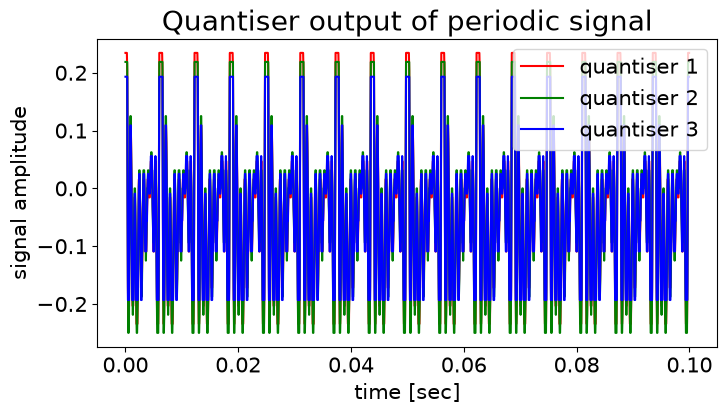

In [15]:
# plot quantisers on periodic signal with B=4, R=0.25
# we use the periodic signal defined at the top of this notebook (called periodic_signal and over time variable t)

# Get each of the quantiser outputs for the periodic signal
quantiser_1_per = quantise1(periodic_signal, B=4, R=0.25)
quantiser_2_per = quantise2(periodic_signal, B=4, R=0.25)
quantiser_3_per = quantise3(periodic_signal, B=4, R=0.25)


plt.figure(figsize=(8,4))
plt.title('Quantiser output of periodic signal')
plt.xlabel('time [sec]')
plt.ylabel('signal amplitude')
plt.plot(t, quantiser_1_per, color='r', label='quantiser 1')
plt.plot(t, quantiser_2_per, color='g', label='quantiser 2')
plt.plot(t, quantiser_3_per, color='b', label='quantiser 3')

plt.legend()
plt.show()        # plot the quantiser[1..3] output for the periodic signal in function of time

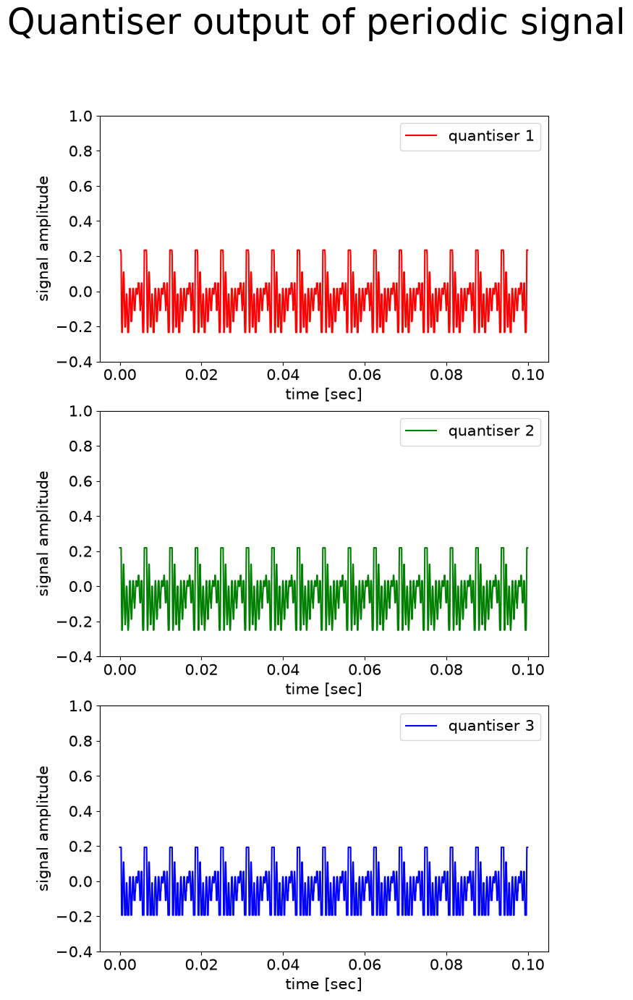

In [16]:
# plot quantisers on periodic signal with B=4, R=0.25
# we use the periodic signal defined at the top of this notebook (called periodic_signal and over time variable t)

# Here we plot the quantiser[1..3] output agian for the periodic signal, but on a different plot so we can compare them better
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8,15))
plt.suptitle('Quantiser output of periodic signal')

for ax in (ax1, ax2, ax3):
    ax.set_ylim(-0.4, 1)
    ax.set_xlabel('time [sec]')
    ax.set_ylabel('signal amplitude')

ax1.plot(t, quantiser_1_per, color='r', label='quantiser 1')
ax1.legend()

ax2.plot(t, quantiser_2_per, color='g', label='quantiser 2')
ax2.legend()

ax3.plot(t, quantiser_3_per, color='b', label='quantiser 3')
ax3.legend()

plt.show()

<div class="alert alert-info">

How do quantiser1 and quantiser2 differ? And how do they differ from quantiser3? Base yourself on the linear and the periodic signals.
</div>

<div class="alert alert-success">

Quantiser 1 and 2 appear to have the same step size (about height 2 / 16 levels = 0.125) however the outputs are shifted relative to each other. The output of quantiser 1 lies higher than that of quantiser 2. For quantiser 1 the output cannot be 0, only a value slightly higher / lower than 0 --> symmetric around 0. For quantiser 2 on the other hand the output can be 0 --> asymmetric around 0. We can read this mostly from the output graph for the linear signal (also a bit on the output for the periodic signal).

Quantiser 3 differs a lot from 1 and 2. The min and max for quantiser 3 lie lower. The steps are non-uniform --> small steps closer to 0 and larger ones farther from 0.



</div>

<div class="sup-step">B.2 Standard PCM</div>

 
A standard PCM (Pulse Code Modulation) codec is simply a quantiser that is applied to $\tds{r} = \tds{x}$. In other words, the model block from [the general schematic](#fig:schematic_ende_coding) does nothing yet.

<div class="alert alert-info">
    
Develop the (trivial) function `xhat = PCM(x, qnt_idx, B, R)` that performs PCM (both encoding and decoding) on a signal  `x` to `xhat` using quantiser **qnt_idx**, scale $R$ and a code length of $\mathcal{B}$ bits per sample.
    
</div>

In [17]:
def PCM(x, qnt_idx, B = 4, R = 1):
    
    xhat = qnt_idx(x, B, R)
    
    return xhat

<div class="sup-step">B.3 Choosing free parameters</div>

Now we will evaluate the free parameters for all three quantisers. First the bith depth $\mathcal{B}$:

<div class="alert alert-info"> 

Plot the evolution of the segmental SNR as a function of $\mathcal{B}$. For this, perform tests with $\mathcal{B} = \bigcb{2, 3, 4, 5, 6, 8, 10, 12}$. Repeat the experiments for all three quantisers.
    
<span> *remember* </span>: free parameter optimisation is done in the development phase, so `develop.wav` should be used.
    
</div>

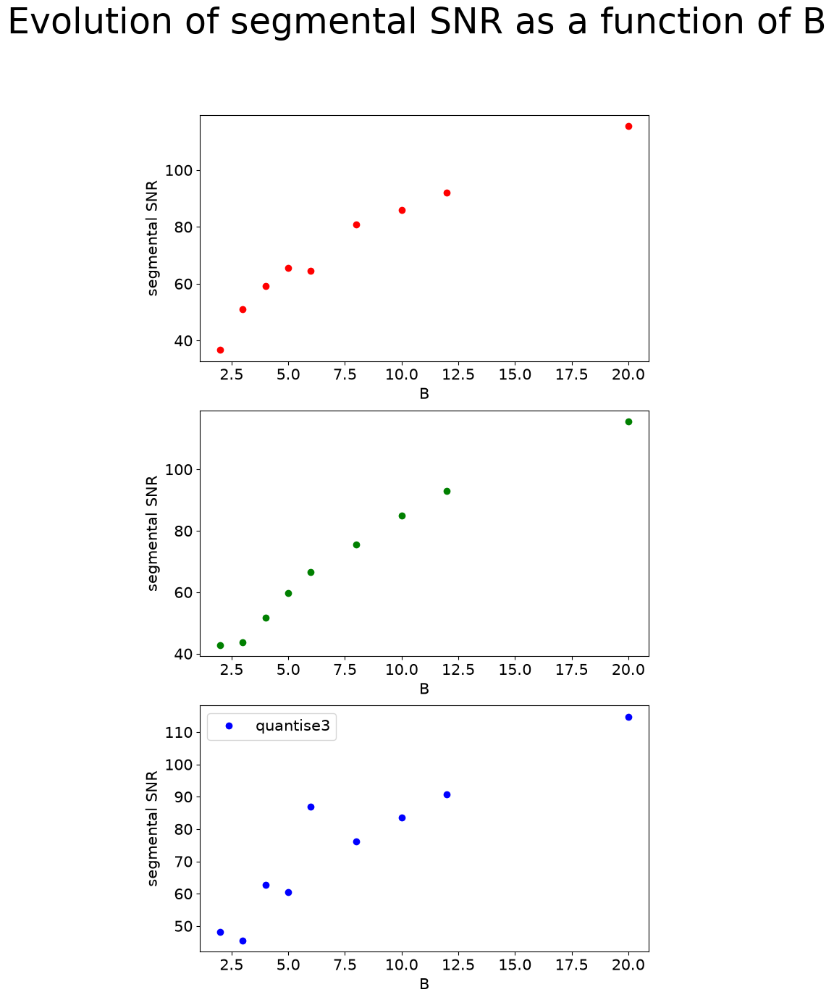

In [18]:
# Plot seg_SNR vs B
B_list = [2, 3, 4, 5, 6, 8, 10, 12, 20]     # make a list of all Bs we want to test
x = develop_signal
seg = np.zeros(len(B_list))   # make a list for eahc of the seg_SNR values

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 15))

plt.suptitle('Evolution of segmental SNR as a function of B')

# quantiser 1
for i, B_element in enumerate(B_list):
    xhat = PCM(x, quantise1, B=B_element)          # the estimated signal xhat = the quantised1( signal )
    seg[i] = estimate_seg_SNR(x, xhat, L = 1)      # calculate the seg_SNR for quantiser 1 for each B
ax1.set_xlabel('B')
ax1.set_ylabel('segmental SNR')
ax1.plot(B_list, seg, 'o', color='r', label='quantise1')


# quantiser 2
for i, B_element in enumerate(B_list):
    xhat = PCM(x, quantise2, B=B_element)         
    seg[i] = estimate_seg_SNR(x, xhat, L = 1)     # calculate the seg_SNR for quantiser 2 for each B
ax2.set_xlabel('B')
ax2.set_ylabel('segmental SNR')
ax2.plot(B_list, seg, 'o', color='g', label='quantise2')

# quantiser 3
for i, B_element in enumerate(B_list):
    xhat = PCM(x, quantise3, B=B_element)
    seg[i] = estimate_seg_SNR(x, xhat, L = 1)      # calculate the seg_SNR for quantiser 3 for each B
ax3.set_xlabel('B')
ax3.set_ylabel('segmental SNR')
ax3.plot(B_list, seg, 'o', color='b', label='quantise3')

plt.legend()

plt.show()

<div class="alert alert-info">

- Discuss your observations for all three quantisers. 
- What is the gain in segmental SNR when the bit-depth is increased by 1 bit?
    
</div>

<div class="alert alert-success">
Increasing the bit-depth B increases the segmental SNR, indicating that the quantised signal xhat better approaches the signal x. For all quantisers the relation seems (almost) linear (in dB). Quantiser 1 and 2 seem similar, with the same slope and almost the same SNR values for different B's. The third quantiser sometimes decreases in accurarcy (lower SNR). 
In the linear region the gain per bith depth is approximately 6 dB

    
For B up till 6 (in this case) the increase in B has a profound effect on the segmental SNR, the xhat better approaches x.


(We have put a limit on the seg_SNR with the minimum(..., 100) in our seg_SNR-function, that is why for higher B the quantised signal quality does not improve)

</div>

Now we will have a first look at the scale factor $R$. We will see how $R$ can be optimised later.

<div class="alert alert-info">

Investigate the effect of all three quantisers on the development file for $\mathcal{B}=4$ and $R=0.5$. Here, use both the segmental SNR and **Listen to the outputs**. Note your observations for ALL quantisers.
    
</div>

In [19]:
# Test effect of lowering R 

print("Original signal")
ipd.display(ipd.Audio(x, rate=Fs)) 

# quantiser 1
print("Quantiser 1")
xhat1 = PCM(develop_signal, quantise1, B=4, R=0.5) 
print(estimate_seg_SNR(x, xhat1, L = 1)) # print the value of the segSNR
ipd.display(ipd.Audio(xhat1, rate=Fs)) # play the quantised signal

# quantiser 2
print("Quantiser 2")
xhat2 = PCM(develop_signal, quantise2, B=4, R=0.5)
print(estimate_seg_SNR(x, xhat2, L = 1)) # print the value of the segSNR
ipd.display(ipd.Audio(xhat2, rate=Fs)) # play the quantised signal


# quantiser 3
print("Quantiser 3")
xhat3 = PCM(develop_signal, quantise3, B=4, R=0.5)
print(estimate_seg_SNR(x, xhat3, L = 1)) # print the value of the segSNR
ipd.display(ipd.Audio(xhat3, rate=Fs)) # play the quantised signal


Original signal


Quantiser 1
65.5918


Quantiser 2
59.65652


Quantiser 3
53.91774


<div class="alert alert-success">
The estimated signal from the third quantisizer sounds the best, we hear the least amount of noise (minimised) and can better understand what is said. The signals from quantiser 1 and 2 have a more prominent noise that can be heard. Even sometimes in signal 2, some sound is absent.
We would expect however from the SNR that signal 3 would sound the worse, because it has the lowest SNR value. This however is not the case.
</div>

<div class="alert alert-info">

Does the segmental SNR correlate to your perceived audio quality? In other words, can the segmental SNR completely replace listening tests?
    
</div>

<div class="alert alert-success">
No, the segmental SNR is pretty high (which means that it better approaches the original signal), however the audio quality is not that good in the 1st and 2nd signals. Signal 3 has a lower SNR, but has better sound quality.
</div>

**From now on, we shall use the quantiser that produces the best-sounding audio.**

<div class="alert alert-info">
Which quantiser do you choose?
</div>

<div class="alert alert-success">
    
We choose quantiser3, because the audio of approximation is the best. The least amount of noise.
</div>

<div class="sup-step">B.4 Optimising $R$</div>

To determine $R$, we start with $R = 1$ (the maximum value) and find the 99.9th *percentile* of the samples of $|r(n)|$. Set $R$ to the value corresponding to this percentile. We will use this function for all subsequent systems.

<div class="alert alert-quiz">
    
Take the short quiz on scale factor R on Ufora
    
</div>

*Hint*: making use of [`np.percentile()`][per] can simplify your code

<div class="alert alert-info">
    
Develop the function `R = determineR(r, percentile)`
    
</div>



[per]: https://numpy.org/doc/stable/reference/generated/numpy.percentile.html

In [20]:
def determineR(r, percentile=99.9):
    
    R = np.percentile(np.abs(r), percentile)
    
    return R

Interestingly, determining $R$ at a lower percentile can give us higher SNR *but* the subsequent quantisation will generate clearly visible and audible artefacts. 

<div class="alert alert-info"> 

Check this for PCM on the development file. Try multiple values of $R$ at different percentiles. Note: common values for $R = \bigcb{0.90, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999}$.
    
</div>

0. R = 0.13227270993094503





1. R = 0.19732173514936477





2. R = 0.2947617412536721





3. R = 0.36808973331807254





4. R = 0.43344397390408607





5. R = 0.513488916866965





6. R = 0.5739956506810118


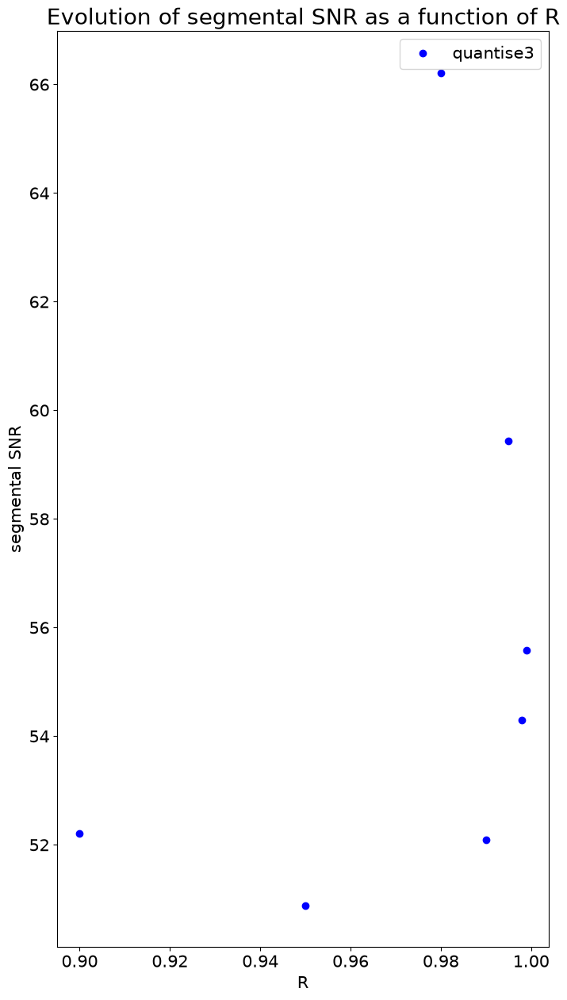

In [21]:
# Plot (and listen to) the development file at with different R's. Also look at their SNRs
R_list = [0.90, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999] # make a list of all Rs we wnat to test

x = develop_signal
R_accent_list = [determineR(x, i*100) for i in R_list]
seg = np.zeros(len(R_list))

plt.figure(figsize=(8, 15))

plt.title('Evolution of segmental SNR as a function of R')

# quantiser 3
for i, R_element in enumerate(R_accent_list):
    xhat = PCM(x, quantise3, R=R_element) # quantise with quantiser3 which we chose earlier
    seg[i] = estimate_seg_SNR(x, xhat, L = 1) # compute the segSNR
    print(f"{i}. R = {R_element}")
    ipd.display(ipd.Audio(xhat, rate=Fs)) # play the estimated signal for each R
    print("\n\n")
    
plt.xlabel('R')
plt.ylabel('segmental SNR')
plt.plot(R_list, seg, 'o', color='b', label='quantise3') # display the segSNR in function of R

plt.legend()

plt.show()

<div class="alert alert-info">
    
Explain what happens. These artefacts cannot be removed even if the bit-depth $B$ is increased. Find an explanation for this.
    
</div>

<div class="alert alert-success">
    
With the quantisers we remove some of the signal value, so we get a worse signal back even if we choose the optimal parameters with the given quantisers.
</div>


<div class="step">C AR-model</div>

<br>
<div class="sup-step">C.1 Implementation the AR-model</div>

You will implement the computation of the coefficient of the AR-model. Remember that the AR model generates a coefficient $a_k$, which can be used to predict the signal based on the previous samples:

\begin{align}
x_p(n) = \sum_{k=1}^K a_k \: x(n-k) 
\label{eq:x_P}
\end{align}

where the coefficients $a_k$ is the solution of the form $\mat{Ga} = \mat{B}$: 

$$
\begin{bmatrix}
    R_{xx}(0) & R_{xx}(1) & \cdots & R_{xx}(K-1)\\
    R_{xx}(1) & R_{xx}(0) & \cdots & R_{xx}(K-2)\\
    \vdots & \vdots & \ddots & \vdots\\
    R_{xx}(-K+1) & R_{xx}(-K+2) & \cdots & R_{xx}(0)\\
\end{bmatrix} 
\begin{bmatrix}
    a_1 \\
    a_2 \\
    \vdots \\
    a_K \\
\end{bmatrix} 
= 
\begin{bmatrix}
    R_{xx}(\textbf{1}) \\
    R_{xx}(2) \\
    \vdots \\
    R_{xx}(K) \\
\end{bmatrix} 
$$

with $R_{xx}(\tau)$ the auto-correlation of at time lag $\tau$. Since the signal is real, this is equal to:

$$
R(\tau) = \sum_{n} \: x(n) \: x(n+\tau) 
$$

First, we show how the auto-correlation for time lag 0 can be implemented using numpy slicing and [numpy.sum][sum]. This will make your code faster. Later in the course, we will also see how the auto-correlation can efficiently be computed via the Fourier Transform.

[sum]: https://numpy.org/doc/stable/reference/generated/numpy.sum.html

In [22]:
#example of calculating autocorrelation at time lag 0.

sig_len = 1000000

a = np.random.rand(sig_len)

R0_loop = 0
for i in range(sig_len-0):
    R0_loop += a[i]*a[i+0]
    
R0_np = np.sum(a[0:]*a[:sig_len-0])

print('{:.5f}'.format(R0_loop/sig_len))
print('{:.5f}'.format(R0_np/sig_len))

0.33359
0.33359


<div class="alert alert-quiz">
    
Take the short quiz on auto-correlation **and** on AR-model on Ufora
    
</div>

<div class="alert alert-info">
    
Realise a function `a = compute_AR_model(x, k)` that determines an AR-model of order $K$ for the signal `x`.
    To find the solution of $\mat{Ga = B}$ for $\mat{a}$ in Python, have a look at [`np.linalg.solve()`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html)  

    
</div>

In [23]:
def compute_AR_model(x, K=1):
    
    # R*(m) = R(-m) !!! so for real valued signals R(m) = R(-m)
    # The prediction is a linear combination of the previous time samples. However, the coefficient by which they are combined are computed making use of the auto-correlation of different time lags in a non-linear manner.
    
    # We assume that x is a real valued signal so R(m) = R(-m)
    sig_len = len(x)
    
    R = np.zeros(K+1)
    for t in range (K+1):
        R[t] = np.sum(x[t:]*x[:sig_len-t])  # make a list with all autocorrelationfunctions index i --> tau = i

    B = R[1:K+1]
    G = np.zeros((K, K))
    
    for i in range(K):
        for j in range(i+1):
            G[i, j] = G[j, i] = R[i - j]    # make the G matrix with the ACFs
    
    a = np.linalg.solve(G, B)  # solve the equation Ga = B

    
    return a

<div class="sup-step">C.2 Testing the AR-model</div>

To test the proper functioning of the code, we provide a test function **`test_compute_AR_model()`**. For that, we first generate a random signal `x = np.random.randn(int(1e6))`, and then filter the signal with a known filter via `sig.lfilter(a, b, x)`, where a and b are the filter coefficients. Don't worry about these for now, later in the course, filtering will be thoroughly explained. For now, it is only important that the output of the filter, $y(n)$ at time $n$ has the following form: $y(n) = x(n) + a(1)y(n-1) + a(2)y(n-2) + a(3)y(n-3)$, where $y(n-k)$ is the output at a previous sample.

In [24]:
# Excecute the test code for different k's

def test_compute_AR_model(k = 3):
    a = np.array([0.5, 0.3, 0.1])        # An AR model with K = 3
    x = np.random.randn(int(1e6))
    y = sig.lfilter(np.array([1]), np.concatenate( ([1],-a) ), x) # Generating the test signal
    aEst = compute_AR_model(y, k)         # Compare aEst and a
    
    # both prints should be similar 
    print('for k={}: the estimated AR-model is {} should be close to {}'.format(k, aEst, a))

for k in [1, 3, 5]:
    test_compute_AR_model(k = k)

for k=1: the estimated AR-model is [0.82684804] should be close to [0.5 0.3 0.1]
for k=3: the estimated AR-model is [0.49759319 0.30150616 0.10085837] should be close to [0.5 0.3 0.1]
for k=5: the estimated AR-model is [4.99014870e-01 3.01033615e-01 1.00138168e-01 6.03273466e-05
 2.78454611e-04] should be close to [0.5 0.3 0.1]


<div class="alert alert-info">
    
Find an explanation as to why the AR-model with k=3 generates the same coefficients as the filter coefficients ($[0.5 , 0.3, 0.1]$). If this is not the case, look back at your implementation.

*hint: look closely at the expression of $y(n)$ after filtering*
     
</div>

<div class="alert alert-success">
The filtering equation is: y(n) = x(n) + 0.5 y(n-1) + 0.3 y(n-2) + 0.1 y(n-3)
The AR model gives a prediction of the signal given previous samples (so the correlation between y(n) and its previous samples). The equation for this was given by x_p(n) = sum(a_k*x(n-k), k=1..K) so for K = 3: y_p(n) = a_1 y(n-1) + a_2 y(n-2) + a_3 y(n-3)

x(n) is noise, so it is uncorrelated with previous samples.
Because the original filter and the AR model have the same form, the best approximation for the coefficients a_1..3 is equal to the filter coefficients ( the equation of the filter is identical to the 3rd order AR-process).
</div>

<div class="alert alert-info">
    
Additionally, explain what happens for the other values of $k$ ($k=1$ and $k = 5$).
     
</div>

<div class="alert alert-success">
For K = 1, the AR-model is y_p(n) = a_1 y(n-1). For this we find a coefficient different from the 1st filter coefficient, 0.5
This can be explained by the fact that the signal consists of 3 previous samples, while the AR-model only consists of 1. So it tries to fit all of the informaction about the other samples (y(n-2) and y(n-3)) into the same one coefficient.

For K = 5, the AR-model consists of 5 previous samples. The first 3 coefficients come very close to the filter coefficients the other 2 are near-zero, because they are not necessary to approximate the original signal.


</div>

<div class="alert alert-info">
    
Now, let's apply the AR model on (unfiltered) white noise. What do you expect the results will be? How will it change with different k's?
     
</div>

In [25]:
for k in  [1, 2, 5, 10]:

    x = np.random.randn(int(1e6))
    aEst = compute_AR_model(x, k)

    print('for k={}: the estimated AR-model is {}'.format(k, aEst))

for k=1: the estimated AR-model is [0.00056375]
for k=2: the estimated AR-model is [0.00084233 0.00070996]
for k=5: the estimated AR-model is [-0.00055552 -0.00245188  0.00051625  0.00147091 -0.00013743]
for k=10: the estimated AR-model is [ 2.86554140e-04  5.82036054e-04 -7.29558699e-04 -1.81044678e-03
  1.39098720e-03 -1.12699924e-03  1.08165832e-03 -1.53958364e-03
 -2.09929439e-05  1.69666279e-04]


<div class="alert alert-info">
    
Explain the results
     
</div>

<div class="alert alert-success">
The AR-model as already said tries to predict the current sample given the previous samples. With "k" we set the amount of previous samples that are used in the model.
Because white noise is uncorrelated, we expect all of the coefficients to be 0. And this independent of the used k. We cannot predict the current sample given the previous samples.
</div>

<div class="sup-step">C.2 Understanding the AR-model</div>


To further understand the AR, we will first focus on making a prediction on $x(n)$ **(different from what will happen in PCM)**. For this, we will use short fragments and compute a separate AR model for each segment. First, let's listen to the fragments (you can also plot them if you want):

In [26]:
ks = getSpeechFragment('assets/audio/ks.wav')
da = getSpeechFragment('assets/audio/da.wav')
wa = getSpeechFragment('assets/audio/wa.wav')

In [27]:
print('\'ks\'')
ipd.display(ipd.Audio(ks, rate=Fs))
print('\'da\'')
ipd.display(ipd.Audio(da, rate=Fs))
print('\'wa\'')
ipd.display(ipd.Audio(wa, rate=Fs))

'ks'


'da'


'wa'


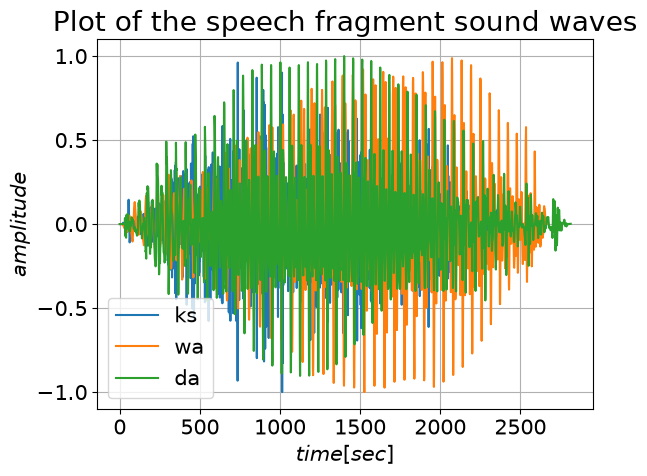

In [28]:
# plot of the different fragments
plt.figure()
plt.plot(ks, label='ks')
plt.plot(wa, label='wa')
plt.plot(da, label='da')

plt.legend()
plt.xlabel('$time [sec]$')
plt.ylabel('$amplitude$')
plt.title('Plot of the speech fragment sound waves')
plt.grid()

Now let's compute the AR model for each segment and plot the coefficients. You can play with the parameter k and see what changes.

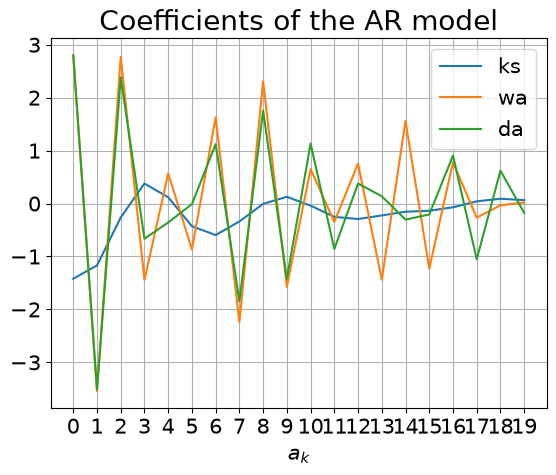

In [29]:
k = 20

a_ks = compute_AR_model(ks, k)
a_wa = compute_AR_model(wa, k)
a_da = compute_AR_model(da, k)

plt.figure()
plt.plot(a_ks, label='ks')
plt.plot(a_wa, label='wa')
plt.plot(a_da, label='da')

plt.legend()
plt.xticks(np.arange(0,k))
plt.xlabel('$a_k$')
plt.title('Coefficients of the AR model')
plt.grid()

<div class="alert alert-info">
    
Note your observations and give a reason as to why this would happen. These coefficients can also be used as discriminative features in speech recognition methods.
     
</div>

<div class="alert alert-success">
There is a clear distinction between the coefficients for these 3 sounds (more prominent for higher k) --> because of this the coefficients can be used as discriminative features in speech recognition methods.
    
We see that the sound "ks" has coefficients closer to 0 whereas wa and da have more fluctuating coefficients farther from 0. Additionally the coefficients for "wa" and "da" have some similarities.
    
The coefficients of "ks" can be explained by the fact that the sound is very noise-like, meaning there isnt much correlation between the different samples. On the other hand, the correlation for the samples of da and wa is greater, resulting in higher positive and negative values. The coefficients of these two are similar because they also sound similar --> they have a more pronounced correlation in time.
</div>

Now we will look at how well the AR-model can predict the next sample:

\begin{align}
x_p(n) = \sum_{k=1}^K a_k \: x(n-k)
\label{eq:x_Pr}
\end{align}

This is implemented below.

We will take a look at how well the AR-model can predict the previous segments with optimised coefficients:

Text(0.5, 1.0, 'SNRs for different number of AR coefficients k')

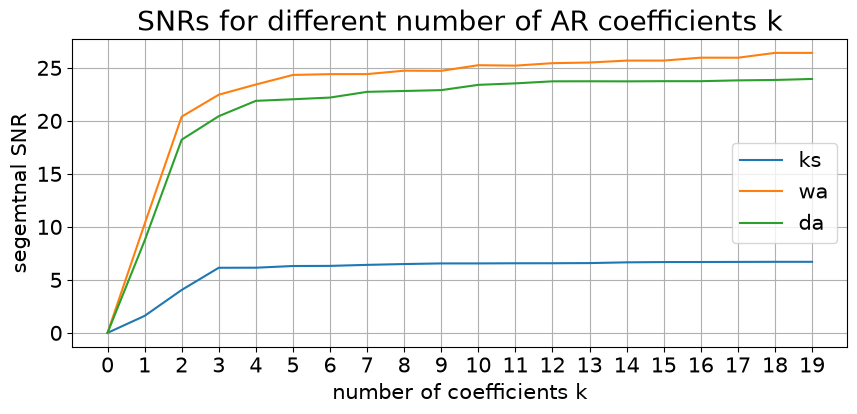

In [30]:
# function to generate all the predictions on x with the AR coefficients a
def get_AR_model_prediction(x, a):
    shifted_signals = np.zeros((len(a), len(x))) 
    for i in range(len(a)):
        shifted_signals[i,i+1:] = x[:-i-1]
    xp_matrix = shifted_signals * a[:,np.newaxis]
    return np.sum(xp_matrix, axis=0) 

#plot SNRs for different number of AR coefficients k
max_k = 20
num_examples = 3
SNRs = np.zeros((num_examples, max_k))

for ex_idx, signal in enumerate([ks, wa, da]):
    for k in range(max_k):
    
        a = compute_AR_model(signal, k)
        signal_hat = get_AR_model_prediction(signal, a)
        SNRs[ex_idx, k] = estimate_seg_SNR(signal, signal_hat)
                   
plt.figure(figsize=(10,4))
for ex_idx, label in enumerate(['ks', 'wa', 'da']):
    plt.plot(SNRs[ex_idx,:], label=label)
    
plt.xticks(np.arange(0,max_k))
plt.grid()
plt.legend()
plt.xlabel('number of coefficients k')
plt.ylabel('segemtnal SNR')
plt.title('SNRs for different number of AR coefficients k')

<div class="alert alert-info">
    
What do you observe now? Discuss the performance change with increasing k and the differences between the different segments.
     
</div>

<div class="alert alert-success">
For smaller number of k, the SNR increases a lot, which means the approximation of the signal becomes a lot better for an increase in the amount of coefficients used
As the value of k increases, the curve flattens --> there is little to no improvement in the signal approximation if we add more past samples
    
For the "ks" fragment the curve flattens around k = 3, the SNR doesnt rise as much in the beginning and doesn't reach a peak as high as the other two sounds. 
This can be explained by the fact that the sound 'ks' is very noise-like meaning there is little correlation between different time samples. Most of the meaningful information about the signal is captured in the first 3 coefficients.

The 'wa' sound has a much bigger increase in SNR before decreasing for higher values of k. This can be explained by the fact that the 'wa' time samples are more correlated to each other. We can better approximate the original signal from the past samples and a better signal approximation if we increase the amount of coefficients.
A similar explanation applies to the 'da' sound.
</div>

Now take a look at the results for when you use a different AR-model to predict the segments: 

In [31]:
k = 5

for signal, label in zip([ks, wa, da], ['ks', 'wa', 'da']):
    
    a = compute_AR_model(signal, k)
    signal_hat = get_AR_model_prediction(da, a)
    SNR = estimate_seg_SNR(da, signal_hat)
    
    print('predicted segment \'da\' with AR model of \'{}\' results in an SNR of {:.3f} dB '.format(label, SNR)) 

predicted segment 'da' with AR model of 'ks' results in an SNR of -10.555 dB 
predicted segment 'da' with AR model of 'wa' results in an SNR of 21.858 dB 
predicted segment 'da' with AR model of 'da' results in an SNR of 22.038 dB 


<div class="alert alert-info">
    
Again discuss the differences. Can you, based on these results, already make predictions on the performance of adaptive encoding compared to static encoding?
     
</div>

<div class="alert alert-success">
From the results we see that the best approximation is found if the signal matches the signal used to train the AR-model. We only observe a small decrease in the qualitiy (0.18 dB)of the prediction if we use a signal for the AR-model that resembles the signal we want to predict (such as 'wa' and 'da').

However when we use two totally different signals for the signal we want to predict and the AR-model we get a bad prediction. Even worse than if we would use only zeros as the signal for the AR-model (-10.555 dB vs 0 dB).

In static encoding a single AR model is chosen and applied everywhere across the signal we want to predict. In adaptive encoding we use different AR-models ('trained' on different signals) that best mach the signal we want to predict around that time frame.

From this we can conclude that we'd get a better performance in adaptive encoding compared to static encoding. Because in static encoding if a signal segment is predicted from a signal that is different from the signal used for the AR-model we get a bad prediction. Adaptive encoding on the other hand uses different AR-signals in time so that we get better predicitions for each signal segment in time.
</div>

<div class="step">D. DPCM</div> 

The DPCM codec uses an AR-model to make a prediction $\tds{x_p}$, of the signal $\tds{x}$ at time $\tmidx$. We assume that both the encoder and decoder have access to the same AR-model. Then, only the prediction *error* $r(n) \triangleq x(n) - x_p(n)$ is encoded via standard PCM (ergo differential). This error should, in the case of a good AR-model, have a smaller dynamic range than the original $x(n)$.  This, in turn, will lead to smaller quantisation errors with the appropriate scale factor $R$. 

In the AR-model, coefficients $a_k, k\in \{1, \cdots, K\}$, are calculated and then used to predict the next sample. Note that the equation is slightly different from before. **$\hat{\textbf{x}}$ is used instead of $\textbf{x}$** since now the signal needs to be sent to the receiver first, and $x(n)$ is not available there.
\begin{align}
x_p(n) = \sum_{k=1}^K a_k \: \hat{x}(n-k)
\end{align}

The encoder will then calculate the error:

$$
r(n) = x(n) - x_p(n),
$$

and send this error to the decoder after quantisation:

$$
\hat{r}(n) = \text{quantise}(r(n))
$$

Since the decoder has the exact same AR-model, the decoder estimates the signal at time $\tmidx$ according to:
\begin{align}
\hat{x}(n) = \hat{r}(n) + x_p(n)
\end{align}

This approach is shown in the next [figure](#fig:DPCM).

<figure id="fig:DPCM">

![figure of DPCM model described in text](assets/figs/DPCM_codec.png "DPCM codec")
<figcaption style="clear: left;margin: .75em 0;text-align: center;font-style: italic;line-height: 1.5em;">
Schematic of a DPCM codec</figcaption>
</figure>

Note that on the encoder side, the prediction $x_p(n)$ is also based on the estimated signal $\hat{x}(n)$. A more accurate prediction could be generated by using $x(n)$. However, since $x(n)$ is not available at the decoder, $\hat{x}(n)$ is chosen so that $x_p(n)$ is calculated in the exact same way as on the decoder side, minimising the decoding error.

<div class="alert alert-info">
    
Realise the functions that perform the DPCM approach: `xhat, r = DPCM(x, B, R, K, a)`. The output `r` will come in handy to later determine the optimal R value. For the decoding, assume that the receiver has an exact copy of the AR-filter. 
    
*Note1: You can not simply copy (part of) the code given in the part on AR-model. $x_p$ and $\hat{x}$ need to be calculated in a loop, since you need $\hat{x}(n-1)$ to make the prediction $x_p(n)$, and you need $x_p(n)$ to get $\hat{x}(n)$.*

    
*Note2: Only the encoder side of the DPCM schematic needs to be realised, since the decoder side generates $\hat{x}(n)$ in the exact same way the encoder does under the condition that no transmission errors occur (which will be assumed).*
     
</div>

In [32]:
def quantise(r, B=4, R=1):         # copy of the third quantiser (see earlier) 
    # Input: r(n)
    # Output r_hat(n)  --> step C and D are taken (q_r(n)) is calculated

    q_r = np.floor(np.sign(r) * ((np.abs(r) / R)**(1/4)) * 2**(B-1))
    q_r = np.clip(q_r, -2**(B-1), 2**(B-1)-1)

    rhat = np.sign(q_r) * np.abs((q_r + 0.5) / (2**(B-1)))**4 * R
    
    return rhat

In [34]:
def DPCM(x, B=4, R=1, K=1, a=np.array([1])):
    if not(len(a) == K):     # a must be equal to K
        return "a must have length K"
        
    len_x = len(x)

    x_hat = np.zeros(len_x + K) # we use a zero-padded list so that we can easily calculate x_p by reversing part of the list
    r = np.zeros(len_x) # empty r-list which we will gradually fill
    
    
    for n in range(len_x):
        x_p = np.dot(a, x_hat[n:n+K][::-1]) # we need to reverse the x_hat 
        r[n] = x[n] - x_p
        r_hat = quantise(r[n], B=B, R=R)
        x_hat[n+K] = r_hat + x_p # we start with x_hat[K] because the first K positions are padding for easier x_p calculation
        
    
    return x_hat[K:], r

<div class="sup-step">D.1 Free parameters</div> 

Now we will look at the free parameters $\mathcal{B}$ and $K$ to determine their optimal values. Remember to optimise the scale $R$ for each pair of $\mathcal{B}$ and $K$. This should be done on the development file before applying the chosen free parameters to the test file. Also, remember to use the AR-model of the development file on the test file in the evaluation stage.

<div class="alert alert-info">
    
1. How does the DPCM method perform for the default values of $\mathcal{B} = 4$ and $K=1$?
    
</div>

In [53]:
# We write a function to get the optimal R for the different values or B and K
def find_optimal_R(B, K, a):
    x = develop_signal
    _, r = DPCM(x, B=B, R=np.max(np.abs(develop_signal)), K=K, a=a)
    
    R_list = [0.90, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999] # make a list of all Rs we wnat to test
    R_accent_list = [determineR(r, i*100) for i in R_list]  # we have to use r(n) to determine the 

    seg = np.zeros(len(R_list))
    for i, R_element in enumerate(R_accent_list):
        xhat, _ = DPCM(x, B=B, R=R_element, K=K, a=a)
        seg[i] = estimate_seg_SNR(x, xhat) # compute the segSNR
        # print(f"{i}. R = {R_element} - segSNR = {seg[i]} dB")

    index_of_best = np.argmax(seg)
    R_optimal = R_accent_list[index_of_best]

    # plt.plot(R_accent_list, seg)
    # plt.xlabel('R'); plt.ylabel('SNR_seg [dB]')
    # plt.title(f'SNR_seg vs R (B={B}, K={K})')
    # plt.show()
    
    xhat, _ = DPCM(x, B=B, R=R_optimal, K=K, a=a)
    # ipd.display(ipd.Audio(xhat, rate=Fs))
    return R_optimal

In [54]:
# Write your experiment here
a = compute_AR_model(develop_signal, K=1) # find the AR-model coefficients

x = test_signal   # define the signal we want to apply DPCM on 
R = find_optimal_R(B=4, K=1, a=a)

xhat, _ = DPCM(x, B=4, R=R, K=1, a=a)
segSNR = estimate_seg_SNR(x, xhat) # compute the segSNR
print(f"For B=4 and K = 1 the segSNR = {segSNR} dB")
ipd.display(ipd.Audio(xhat, rate=Fs))

25.77333


<div class="alert alert-success">
    
For B=4 and K=1 with optimised R, we get a segSNR of 25.77333 dB between the approximated and the original test-signal. This is fairly high, so the approximated signal should sound like the original test signal.     
From the sound fragment of the approximated test-signal we hear that our observations from the SNR are confirmed. The amount of crackling and noise are reduced, except for some noise-like sounds "sh" / "ks". We already found the reason for this earlier (they are noise-like with little correlation in time and cannot be predicted with high accuracy. A single AR-coefficient can only capture little correlation so these segments still have a large prediction error).
</div>

<div class="alert alert-info">
    
2. How does the method perform as a function of $K$? Compare the performance of this method for $K = 1, 2, 4, 8$ with that of the standard PCM ($K=0$). Mainly, listen to the signal. The defined segmental SNR is too coarse to catch all the different artefacts. 
    
</div>

In [55]:
def optimal_R_PCM():
    R_list = [0.90, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999] # make a list of all Rs we wnat to test
    
    x = develop_signal
    R_accent_list = [determineR(x, i*100) for i in R_list]
    seg = np.zeros(len(R_list))

    # quantiser 3
    for i, R_element in enumerate(R_accent_list):
        xhat = PCM(x, quantise3, R=R_element, B=4) # quantise with quantiser3 which we chose earlier
        seg[i] = estimate_seg_SNR(x, xhat) # compute the segSNR
        
    
    index_of_best = np.argmax(seg)
    R_optimal = R_accent_list[index_of_best]

    return R_optimal

In [56]:
# Write your experiment here
print("K = 0")
R_PCM_opt = optimal_R_PCM()
xhat0 = PCM(test_signal, quantise3, B=4, R=R_PCM_opt)

print(estimate_seg_SNR(test_signal, xhat0)) # display the segSNR
ipd.display(ipd.Audio(xhat0, rate=Fs)) # play the quantised signal

K_list = [1, 2, 4, 8, 16]
for k in K_list:
    a = compute_AR_model(develop_signal, K=k) # find the AR-model coefficients
    R = find_optimal_R(B=4, K=k, a=a)

    xhat, _ = DPCM(test_signal, B=4, R=R, K=k, a=a)
    
    print("\n\n\n")
    print(f" K = {k}")
    print(f"segSNR = {estimate_seg_SNR(test_signal, xhat)} dB")
    ipd.display(ipd.Audio(xhat, rate=Fs))

K = 0
13.82853






 K = 1
25.77333






 K = 2
26.32356






 K = 4
25.30712






 K = 8
26.77028






 K = 16
27.56049


<div class="alert alert-success">
The approximated test-signal reaches a SNR-seg of 13.83 dB while it is 25.77 dB, 26.32 dB, 25.31 dB and 26.77 dB for K = 1, 2, 4 and 8 respectively. The largest increase in SNR is for K = 0 to K = 1 (PCM to DPCM). We can also hear this difference audibly, there is much less crackling and noise (especially for the "s" sounds). Increasing K only delivers small improvements, with K = 8 having the highest SNR. However when listening to the different predictions we cannot hear much of a difference. Only a slight increase in sound-quality. A larger K uses more coefficients in the AR-model, meaning it captures more of the correlation in the signal, but the gain in signal improves only slightly (this can be seen on snr vs K graph seen earlier). Noise-like sounds, like s, are still predicted because they have little correlation in time.
</div>

<div class="alert alert-info">
    
    
3. What $K$ delivers a good compromise between quality and computational effort? You may estimate the computational effort as a function of the number of operations (additions and multiplications) required. 
    
</div>

<div class="alert alert-success">
    
Most of the computations are made when calculating x_p(n) --> roughly 2K operations. 
Most of the increase is in going from PCM to DPCM so we choose K >= 1. 
The SNR increases 0.5 dB in going from K = 1 to K = 2, with only 2 more operations. We choose K = 2 as a compromise. because choosing a higher K means little to no improvement but a lot more computations.
(if the amount of computations is the most important factor we would choose K = 1)
</div>

<div class="alert alert-info">
    
    
4. For this $K$, what is the minimum value of $\mathcal{B}$ for which the result is acceptable for commercial use?
    
</div>

In [57]:
# Write your experiment here
B_list = np.arange(1, 10)
k = 2
a = compute_AR_model(develop_signal, K=k) # find the AR-model coefficients
SNR_list = []

for b in B_list:
    R = find_optimal_R(B=b, K=k, a=a)

    xhat, _ = DPCM(test_signal, B=b, R=R, K=k, a=a)

    print("\n\n\n")
    print(f" B = {b}")
    SNR = estimate_seg_SNR(test_signal, xhat)
    SNR_list.append(SNR)
    print(f"segSNR = {SNR} dB")
    ipd.display(ipd.Audio(xhat, rate=Fs))

plt.plot(B_list, SNR_list)
plt.xlabel('B [#]'); plt.ylabel('SNR_seg [dB]')
plt.grid(True)
plt.show()





 B = 1
segSNR = 1.2384 dB






 B = 2
segSNR = 12.86818 dB






 B = 3
segSNR = 19.84229 dB






 B = 4
segSNR = 26.32356 dB






 B = 5
segSNR = 32.37244 dB






 B = 6
segSNR = 38.28632 dB






 B = 7
segSNR = 44.23518 dB






 B = 8
segSNR = 50.20713 dB






 B = 9
segSNR = 56.14789 dB


<div class="alert alert-success">
    
We can see that the amount of bits has a profound effect on the quality of the approached signal. Increasing the B value increases the segSNR a lot and we can hear a big improvement in sound quality, for a bigger B we get a hear less noise, the 's' sounds cannot be predicted correctly.
When we listen to the different sound fragments, we find that for B=4 the quality is acceptable but not good enough for commercial use. For B = 5 the quality is even better (SNR and sound-wise) and is just enough for commercial use.

</div>

<div class="step">E. Adaptive predictive encoding of speech</div>

The DPCM codec we have just implemented is sub-optimal because the AR-model it uses is estimated on the average properties of the signal. Since speech is a non-stationary signal, we can assume that we will obtain better results with an AR-model that can *adapt* to the signal (thus capturing local variations).

In the following, we shall look at three systems that can do this. One of these systems will be implemented for you, one should be implemented by yourselves, whereas the last approach shall be demonstrated in the last topic of the course. Stay tuned for that!

The codec still works according to the general schematic of DPCM ([Fig. DPCM](#fig:DPCM)), but with the modification that the AR-model is regularly updated. (Note that the *estimation* of the AR-model is *not* depicted in the figure.)

Note: for the implementation of the following functions, also check out [Possible problems that can occur](#Possible-problems-that-can-occur)

<br>
<div class="sup-step">E.1 Buffered system</div> 

In this approach, the signal is divided into segments of length $M$ and the samples in each segment $m$ are encoded using the AR-model for the *previous* segment. By reducing $M$, we can update the model more frequently. However, this comes at a price: the ACF computed on very short segments is not reliable (too few samples for reliable statistics). This can be balanced out by including samples from before that segment. We will include $N > M$ samples.

The AR-model for segment $m$ is determined based on the estimate of the auto-correlation function (ACF) from the samples of $\tds{x}$ for $\tmidx \in \bigcb{mM-N,mM -1}$. It can be shown that such AR-model minimises the following error:
$$
E(m) = \sum_{i=mM+1-N}^{mM}[\hat{x}(i) - x_p(i)]^2, \quad 
x_p(i) = \sum_{k=1}^K \: a_k \: \hat{x}(i-k) 
$$
This is under the assumption that $\tds[i]{\hat{x}} = 0$ for $i<0$ in the above equation.

 The following systems demonstrate a different compromise.

In [61]:
def APC_buf(x, B=4, K=1, M=160, N=400, R=1):
    
    # create empty array for xhat and r
    xhat = np.zeros_like(x)
    r    = np.zeros_like(x)
    
    # calculate the amount of segement the AR-model has te be recomputed for
    amount_segments = len(x)//M 
    
    # first block has no data available
    a = np.zeros(K)
    xhat[0:M], r[0:M] = DPCM(x[0: M], B, R, K, a)
    
    #start from the second segment
    for i_seg in range(1, amount_segments):
        
        # make sure the indeces are always within the array sizes
        lower = max(i_seg*M-N, 0)
        upper = min(i_seg*M-1, x.size)
        
        a = compute_AR_model(x[lower:upper+1], K) # from m*M - N to m*M - 1 inclusive
        
        # segment on which the new AR model is performed. 
        # Note: K samples before the segment need to be include so the code can properly use the AR-model from the first sample
        x_hat_long, r_long = DPCM(x[i_seg*M-K:(i_seg+1)*M], B, R, K, a) 
        
        # Remove the first K samples again so only the valid segment is kept
        xhat[i_seg*M:(i_seg+1)*M] = x_hat_long[K:]
        r[i_seg*M:(i_seg+1)*M] = r_long[K:]
        
    return xhat, r

<div class="alert alert-info">

Use the buffered system on the **periodic signal** for $\mathcal{B}=4$ and $R = 0.5$. Comment on what you see. What are differences with PCM and DPCM?
</div>

In [63]:
# Write your testcode here
print("Original signal")
ipd.display(ipd.Audio(periodic_signal, rate=Fs))
print("\n\n")

xhat_PCM = PCM(periodic_signal, quantise3, B=4, R=0.5)

print("PCM")
SNR = estimate_seg_SNR(periodic_signal, xhat_PCM)
print(f"segSNR for PCM = {SNR} dB")
ipd.display(ipd.Audio(xhat_PCM, rate=Fs))
print("\n\n")


a_DPCM = compute_AR_model(periodic_signal, K=1) # find the AR-model coefficients
xhat_DPCM, _ = DPCM(periodic_signal, B=4, R=0.5, K=1, a=a_DPCM)

print("DPCM")
SNR = estimate_seg_SNR(periodic_signal, xhat_DPCM)
print(f"segSNR for DPCM = {SNR} dB")
ipd.display(ipd.Audio(xhat_DPCM, rate=Fs))
print("\n\n")


xhat_buf, r_buf = APC_buf(periodic_signal, B = 4, R = 0.5)

print("Buffered system")
SNR = estimate_seg_SNR(periodic_signal, xhat_buf)
print(f"segSNR for buffered system = {SNR} dB")
ipd.display(ipd.Audio(xhat_buf, rate=Fs))
print("\n\n")

Original signal





PCM
segSNR for PCM = 6.32693 dB





DPCM
segSNR for DPCM = 23.15995 dB





Buffered system
segSNR for buffered system = 22.35271 dB


<div class="alert alert-success">
When we compare the different approximations, especially at a lower playback speed, we find that the original signal is best approximated with the buffered system.
The PCM-approximation doesn't match the original signal at all, SNR and sound-wise. The SNR is very low and the approximation has a much higher pitch.
The DPCM and buffered system approximation closely resemble the original periodic signal. We cannot hear much of a difference especially, only in the last millisecond does the buffered system approximation cut off slightly better. This is not what we expect from our segSNR output however.

</div>

<div class="alert alert-info">

Is this a causal system? Explain
</div>

<div class="alert alert-success">
    
Yes, the system is causal --> it only uses past signal values.
The AR-model for segment $m$ is determined based on the estimate of the auto-correlation function (ACF) from the samples of $\tds{x}$ for $\tmidx \in \bigcb{mM-N,mM -1}$ which all lie before the first sample of segment m
and x_p(n) within the segment only uses earlier reconstructed samples $ \hat{x}(n-k)$
</div>

<div class="sup-step">E.2 Recursive systems</div> 

In the buffered approach, the computation of the ACF and the model update (i.e. solving the linear equations) are concentrated at time instants $\tmidx=mM$. This has two consequences:
1. The computational load increases at time-instants $\tmidx=mM$ and is low for other time instants (inefficient use of resources)
2. The updates at discrete instants in time can lead to sudden jumps in the model, especially at the boundaries of different phonemes.

In this approach, we will solve the first problem by recursively estimating the ACFs. The cost function is then reformulated as:
$$
E(n) = \sum_{i=-\infty}^n \alpha^{n-i} \: [\hat{x}(i) - x_p(i)]^2, \quad 
x_p(i) = \sum_{k=1}^K \: a_k \: \hat{x}(i-k), \quad
0 < \lambda < 1
$$
We can estimate the elements of $\mat{G}$ and $\mat{B}$ on a sample-by-sample basis (computational cost is more evenly spread across all time-instants). However, solving for $\mat{Ga}=\mat{B}$ more frequently (which reduces jumps in the model parameters) is still computationally expensive because of the needed matrix inverse. Therefore, the AR-model will still only be updated every $M$ samples.

$\mat{G}$ and $\mat{B}$ can be updated recursively as:
\begin{align}
\tds{G_{lk}} & = \alpha \tds[\tmidx-1]{G_{lk}} + \tds[\tmidx-k]{\hat{x}}\tds[\tmidx-l]{\hat{x}}\\
\tds{B_k}    & = \alpha \tds[\tmidx-1]{B_k}    + \tds{\hat{x}}\tds[\tmidx-k-\mathbf{1}]{\hat{x}}
\end{align}

Note the extra '-1' (in bold) in the update formula of $\tds{B_k}$. Do you see the reason why?

Here, the parameter $\alpha$ determines the &lsquo;memory&rsquo; of the system (i.e. how long past samples are allowed to significantly influence the $E(n)$ and, consequently, the AR-model parameters). One could also interpret $\lambda$ in terms of a time-constant as $e^{-\tsamp/\tau_{\lambda}}$. The time-constant (expressed in samples as $\tau_{\lambda}/\tsamp$) serves the same purpose as the length $N$ in the case of the buffered system.

<div class="alert alert-quiz">

Take the short quiz on APC (adaptive predictive coding) on Ufora
    
</div>

<div class="alert alert-info">

Realise the function `xhat, r = APC_rec(x, B, K, M, lambda, R)` that implements the codec via the recursive method.
    
</div>

In [82]:
def APC_rec(x, B=4, K=1, M=160, tau=0.025, R=1):
    Ts = 1/Fs
    alpha = np.exp(-Ts/tau)

    # create empty array for xhat and r
    x_hat = np.zeros(len(x)+K) # with 0 padding for easer calculations
    r = np.zeros_like(x)
    
    G = np.zeros((K, K)) # G is 2 dimensional with dimension K x K
    B_matrix = np.zeros(K)   # B_matrix is K-dimensional
    a = np.zeros(K)

    for n in range(len(x)):
        # we need update the AR-model every M samples --> see quiz "The inversion of G still needs to happen at each M samples. "
        if (n % M == 0):
            if (n > 0):     # for n = 0 B is a singular matrix
                a = np.linalg.solve(G, B_matrix)  # solve the equation Ga = B

        # calculate x_p(n) (just like in the previous AR-model code)
        x_p = np.dot(a, x_hat[n:n+K][::-1])

        # calculate r[n] & xhat[n] --> seee DCPM schema
        r[n] = x[n] - x_p
        r_hat = quantise(r[n], B=B, R=R)
        x_hat[n+K] = r_hat + x_p # we start x_hat at index K --> we will slice this later, but laats toe to do easier calculations

        for k in range(K):
            for l in range(K):
                G[l, k] = alpha * G[l, k] + x_hat[n-k+K-1] * x_hat[n-l+K-1]
            B_matrix[k] = alpha * B_matrix[k] + x_hat[n+K]*x_hat[n-k-1+K]
            
    return x_hat[K:], r

In [83]:
# def APC_rec(x, B=4, K=1, M=160, tau=0.025, R=1):
#     Ts = 1/Fs
#     alpha = np.exp(-Ts/tau)

#     x_hat = np.zeros_like(x)
#     r = np.zeros_like(x)

#     amount_segments = len(x) // M

#     a = np.zeros(K)
#     xhat[0:M], r[0:M] = DPCM(x[0:M], B, R, K, a)

#     for i_seg in range(1, amount_segments):
        

#     return x_hat, r

In [84]:
# def APC_rec(x, B=4, K=1, M=160, tau=0.025, R=1):
    
#     Ts = 1/Fs
#     alpha = np.exp(-Ts/tau)
    
#     raise NotImplementedError
    
#     return x_hat, r

<div class="alert alert-info">

Validate the functionality of the approach on the **periodic signal** for $\mathcal{B}=4$ and $R = 0.5$. comment on what you see!
    
</div>

In [85]:
# Write your testcode here
print("Original signal")
ipd.display(ipd.Audio(periodic_signal, rate=Fs))
print("\n\n")

xhat_PCM = PCM(periodic_signal, quantise3, B=4, R=0.5)

print("PCM")
SNR = estimate_seg_SNR(periodic_signal, xhat_PCM)
print(f"segSNR for PCM = {SNR} dB")
ipd.display(ipd.Audio(xhat_PCM, rate=Fs))
print("\n\n")


a_DPCM = compute_AR_model(periodic_signal, K=1) # find the AR-model coefficients
xhat_DPCM, _ = DPCM(periodic_signal, B=4, R=0.5, K=1, a=a_DPCM)

print("DPCM")
SNR = estimate_seg_SNR(periodic_signal, xhat_DPCM)
print(f"segSNR for DPCM = {SNR} dB")
ipd.display(ipd.Audio(xhat_DPCM, rate=Fs))
print("\n\n")


xhat_rec, r_rec = APC_rec(periodic_signal, B = 4, R = 0.5)

print("Recursive system")
SNR = estimate_seg_SNR(periodic_signal, xhat_rec)
print(f"segSNR for recursive system = {SNR} dB")
ipd.display(ipd.Audio(xhat_rec, rate=Fs))
print("\n\n")



# Write your testcode here
print("Original signal")
ipd.display(ipd.Audio(test_signal, rate=Fs))
print("\n\n")

xhat_rec, r_rec = APC_rec(test_signal, B = 4, R = 0.5)

print("Recursive system")
SNR = estimate_seg_SNR(test_signal, xhat_rec)
print(f"segSNR for recursive system = {SNR} dB")
ipd.display(ipd.Audio(xhat_rec, rate=Fs))
print("\n\n")

Original signal





PCM
segSNR for PCM = 6.32693 dB





DPCM
segSNR for DPCM = 23.15995 dB





Recursive system
segSNR for recursive system = 22.91494 dB





Original signal





Recursive system
segSNR for recursive system = 25.6664 dB


<div class="alert alert-success">

X For the periodic signal the ...

</div>

<div class="alert alert-info">

Did you implement a causal system? Explain. Also explain what the advantage is of your system
</div>

<div class="alert alert-success">
    
Yes, we implemented a causal system --> the system again only uses past values.
The x_p(n) is again only calculated based on earlier constructed samples ($x_p(i) = \sum_{k=1}^K \: a_k \: \hat{x}(i-k), \quad$).
The matrices G and B are also calculated recursively with past values and a present value xhat(n) which by then has already been calculated
\begin{align}
\tds{G_{lk}} & = \alpha \tds[\tmidx-1]{G_{lk}} + \tds[\tmidx-k]{\hat{x}}\tds[\tmidx-l]{\hat{x}}\\
\tds{B_k}    & = \alpha \tds[\tmidx-1]{B_k}    + \tds{\hat{x}}\tds[\tmidx-k-\mathbf{1}]{\hat{x}}
\end{align}

The advantage of this recursive APC system compared to the previous buffered system is that G and B are updated at each sample  --> solving the matrix equation does still happen each M samples however
So the auto correlation does not need to be calculated at the same time as the inversion of matrix G. meaning the computations are more spread out over all time instances. Old samples gradually dont' play a role anymore because of alpha.
</div>

<div class="sup-step">E.3 RLS: Recursive least squares (later in the course)</div> 

In the previous section, the elements $\mat{G}$ and $\mat{B}$ are updated on a sample-by-sample basis. However, if we want to compute the AR coefficients $\mat{a}$ also on a sample-by-sample basis, it requires a solution of $\mat{Ga}=\mat{B}$ for each time-instant $\tmidx$. Since this requires the computation of a matrix inverse, it can be computationally quite demanding. In the last topic in this course, we shall see a method that recursively updates $\mat{G}^{-1}$ directly, thus reducing the computational load by removing the need for matrix inversion.

<div id='Possible-problems-that-can-occur' class="sup-step">E.4 Possible problems that can occur</div> 

If the methods discussed above are directly implemented, the following issues could arise in practice for segments where the signal is very weak (low-amplitude):

1. If the smallest possible quantisation step is still larger than the signal amplitude, the system will *oscillate*, which will give the quantisation error signal a *tonal* characteristic.
Such tonal noise can be perceptually quite annoying.
2. The matrix $\mat{G}$ can become *singular*, leading to poor performance in the short-term.

Solutions exist for both these problems:

1. If $\mathcal{B}$ is not very small, the tonal noise can be suppressed by a good choice of the quantiser (i.e. properly choosing between quantisers 1 $\ldots$ 3). In case the signal still contains disturbing musical/harmonic components in the quantisation noise, *dithering* is an option. Dithering means that a small amount of uniformly distributed noise is added to the signal $\tds{r}$ *before* quantisation. Of course, the more noise that is added, the lower the SNR will be. Therefore, the added noise is in the range $\bigsb{-\epsilon_d \Delta,\,\epsilon_d \Delta}$ where $\Delta = R/2^{\mathcal{B}-1}$ is the quantisation step and $\epsilon_d \approx 0.125$. Example code for dithering on a sample per sample basis is given below. You can use this or modify it to suit your code.
2. Singularities in the solution of $\mat{Ga}=\mat{B}$ can be prevented by the approach of *diagonal loading*, whereby a small constant $G_0$ is added to the diagonals of $\mat{G}$ before computing the inverse. Note that this addition is only done at the moment of computing the inverse. It does not remain a part of $\mat{G}$ during the updates (i.e. we solve $\bignp{\mat{G}+G_0\mat{I}}\mat{a}=\mat{B}$, where $\mat{I}$ is the identity matrix).

This is also known as the *Tikhonov* or the *$L_2$-regularisation*.

Below is an implementation of the dither for one sample. You can implement a similar function with numpy for faster computation making use of [`numpy.random.uniform`][uniform].

[uniform]: https://numpy.org/doc/stable/reference/random/generated/numpy.random.uniform.html

In [75]:
def dither(sample, B, R):
    eps_d = 0.125
    Delta = R/2**(B-1)
    sample += rng.uniform(-eps_d*Delta,eps_d*Delta)

    return sample

# use:

# for r_i in r:
#     r_i = dither(r_i, B, R)
#     r_i_hat = quantise<123>(r_i, B, R)

In [112]:
# Corrected code !!!!!!!!
def APC_rec(x, B=4, K=1, M=160, tau=0.025, R=1):

    G_0 = 1E-6 # NEW CONSTANT FOR SINGULARITIES
    
    Ts = 1/Fs
    alpha = np.exp(-Ts/tau)

    # create empty array for xhat and r
    x_hat = np.zeros(len(x)+K) # with 0 padding for easer calculations
    r = np.zeros_like(x)
    
    G = np.zeros((K, K)) # G is 2 dimensional with dimension K x K
    B_matrix = np.zeros(K)   # B_matrix is K-dimensional
    a = np.zeros(K)

    for n in range(len(x)):
        # we need update the AR-model every M samples --> see quiz "The inversion of G still needs to happen at each M samples. "
        if (n % M == 0):
            if (n > 0):     # for n = 0 B is a singular matrix

                # SINGULARITIES --> adjusted        
                a = np.linalg.solve(G + G_0*np.identity(K), B_matrix)  # solve the equation Ga = B

        # calculate x_p(n) (just like in the previous AR-model code)
        x_p = np.dot(a, x_hat[n:n+K][::-1])

        # calculate r[n] & xhat[n] --> seee DCPM schema
        r[n] = x[n] - x_p

        # DITHERING --> adjusted        
        r_hat = quantise(dither(r[n], B, R), B=B, R=R)

        
        x_hat[n+K] = r_hat + x_p # we start x_hat at index K --> we will slice this later, but laats toe to do easier calculations

        for k in range(K):
            for l in range(K):
                G[l, k] = alpha * G[l, k] + x_hat[n-k+K-1] * x_hat[n-l+K-1]
            B_matrix[k] = alpha * B_matrix[k] + x_hat[n+K]*x_hat[n-k-1+K]
            
    return x_hat[K:], r

In [113]:
def compute_AR_model(x, K=1):
    
    # R*(m) = R(-m) !!! so for real valued signals R(m) = R(-m)
    # The prediction is a linear combination of the previous time samples. However, the coefficient by which they are combined are computed making use of the auto-correlation of different time lags in a non-linear manner.
    
    # We assume that x is a real valued signal so R(m) = R(-m)
    sig_len = len(x)
    
    R = np.zeros(K+1)
    for t in range (K+1):
        R[t] = np.sum(x[t:]*x[:sig_len-t])  # make a list with all autocorrelationfunctions index i --> tau = i

    B = R[1:K+1]
    G = np.zeros((K, K))
    
    for i in range(K):
        for j in range(i+1):
            G[i, j] = G[j, i] = R[i - j]    # make the G matrix with the ACFs

    # SINGULARITIES --> adjusted
    G_0 = 1E-6 # NEW CONSTANT FOR SINGULARITIES
    a = np.linalg.solve(G + G_0*np.identity(K), B)  # solve the equation Ga = B

    
    return a


<div class="sup-step">E.5 Free parameters</div> 

The free parameters are now $R$, $K$, $\mathcal{B}$, $G_o$, $M$ and $N$ or $\tau_{\lambda}$. For each experiment we shall start with the default values ($\mathcal{B} = 4$, $K = 1$, $M = 160$ (= 10$\unit{ms}$), $N = 400$ (= 25$\unit{ms} $= 0.025$\unit{s}$), $\tau_{\alpha} = 25\unit{ms}$,
$G_0 = 0.0001$) and systematically adjust one parameter at a time. To determine $R$, again perform the selected feature set first on the development file and evaluate on the test file.

<div class="alert alert-info">

Now we shall successively optimise $K$, $M$ and $\tau_{\alpha}$ (or $N$). For this, we shall carry out the appropriate experiments on the speech signal to try to answer the following questions. Remember to keep the computational effort/cost in mind when choosing the &lsquo;optimal&rsquo; parameters.
    
    
1. Compare the performance of the buffered and the recursive methods (after their respective optimisation of $R$) as a function of $K$. Take $K = 1, 2, 4, 8$. Is the evolution different from that with DPCM?

    
</div>

In [114]:
# We write a function to get the optimal R for the different values or B and K
def find_optimal_R_rec(B, K, M=160, tau=0.025):
    _, r = APC_rec(develop_signal, B=B, K=K, R=np.max(np.abs(develop_signal)), M=M, tau=tau)
    
    R_list = [0.90, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999] # make a list of all Rs we wnat to test
    R_accent_list = [determineR(r, i*100) for i in R_list]  # we have to use r(n) to determine the 

    seg = np.zeros(len(R_list))
    for i, R_element in enumerate(R_accent_list):
        xhat, _ = APC_rec(develop_signal, B=B, R=R_element, K=K, M=M, tau=tau)
        seg[i] = estimate_seg_SNR(develop_signal, xhat) # compute the segSNR
        # print(f"{i}. R = {R_element} - segSNR = {seg[i]} dB")

    index_of_best = np.argmax(seg)
    R_optimal = R_accent_list[index_of_best]

    # plt.plot(R_accent_list, seg)
    # plt.xlabel('R'); plt.ylabel('SNR_seg [dB]')
    # plt.title(f'SNR_seg vs R (B={B}, K={K})')
    # plt.show()
    
    # xhat, _ = APC_rec(develop_signal, B=B, R=R_optimal, K=K)
    # ipd.display(ipd.Audio(xhat, rate=Fs))
    return R_optimal

In [115]:
# We write a function to get the optimal R for the different values or B and K
def find_optimal_R_buf(B, K, M=160, N=400):
    _, r = APC_buf(develop_signal, B=B, K=K, R=np.max(np.abs(develop_signal)), M=M, N=N)
    
    R_list = [0.90, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999] # make a list of all Rs we wnat to test
    R_accent_list = [determineR(r, i*100) for i in R_list]  # we have to use r(n) to determine the 

    seg = np.zeros(len(R_list))
    for i, R_element in enumerate(R_accent_list):
        xhat, _ = APC_buf(develop_signal, B=B, R=R_element, K=K, M=M, N=N)
        seg[i] = estimate_seg_SNR(develop_signal, xhat) # compute the segSNR
        # print(f"{i}. R = {R_element} - segSNR = {seg[i]} dB")

    index_of_best = np.argmax(seg)
    R_optimal = R_accent_list[index_of_best]

    # plt.plot(R_accent_list, seg)
    # plt.xlabel('R'); plt.ylabel('SNR_seg [dB]')
    # plt.title(f'SNR_seg vs R (B={B}, K={K})')
    # plt.show()
    
    # xhat, _ = APC_buf(test_signal, B=B, K=K, M=M, N=N, R=R_optimal)
    # ipd.display(ipd.Audio(xhat, rate=Fs))
    return R_optimal

Buffered method
 K = 1
segSNR = 28.48194 dB




Recursive method
 K = 1
segSNR = 28.73585 dB






Buffered method
 K = 2
segSNR = 30.86562 dB




Recursive method
 K = 2
segSNR = 31.27028 dB






Buffered method
 K = 4
segSNR = 32.58843 dB


C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:39: RuntimeWarning: overflow encountered in scalar add
  G[l, k] = alpha * G[l, k] + x_hat[n-k+K-1] * x_hat[n-l+K-1]
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:40: RuntimeWarning: overflow encountered in scalar multiply
  B_matrix[k] = alpha * B_matrix[k] + x_hat[n+K]*x_hat[n-k-1+K]
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:39: RuntimeWarning: overflow encountered in scalar multiply
  G[l, k] = alpha * G[l, k] + x_hat[n-k+K-1] * x_hat[n-l+K-1]
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:40: RuntimeWarning: invalid value encountered in scalar add
  B_matrix[k] = alpha * B_matrix[k] + x_hat[n+K]*x_hat[n-k-1+K]
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:39: RuntimeWarning: invalid value encountered in scalar add
  G[l, k] = alpha * G[l, k] + x_hat[n-k+K-1] * x_hat[n-l+K-1]
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\642081425.py:24: RuntimeWa

Recursive method
 K = 4
segSNR = nan dB


C:\Users\senhu\AppData\Roaming\Python\Python314\site-packages\IPython\lib\display.py:187: RuntimeWarning: invalid value encountered in cast
  return scaled.astype("<h").tobytes(), nchan






Buffered method
 K = 8
segSNR = 33.96244 dB


C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\270041431.py:5: RuntimeWarning: overflow encountered in scalar divide
  q_r = np.floor(np.sign(r) * ((np.abs(r) / R)**(1/4)) * 2**(B-1))
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:26: RuntimeWarning: overflow encountered in dot
  x_p = np.dot(a, x_hat[n:n+K][::-1])
C:\Users\senhu\AppData\Local\Temp\ipykernel_28108\968887783.py:26: RuntimeWarning: invalid value encountered in dot
  x_p = np.dot(a, x_hat[n:n+K][::-1])


Recursive method
 K = 8
segSNR = nan dB


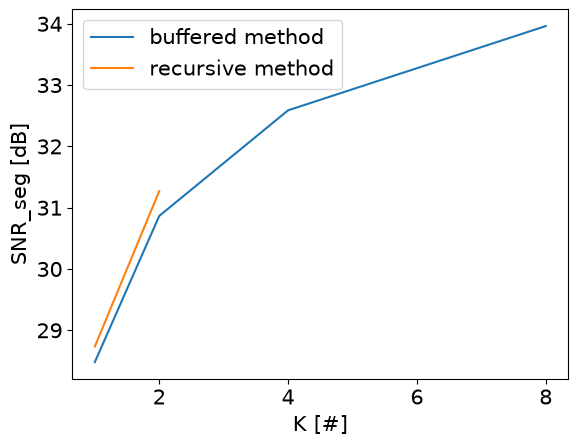

In [116]:
# Write your testcode here
K_list = [1, 2, 4, 8]

SNR_buf_list = []
SNR_rec_list = []

for k in K_list:
    # Buffered method
    R_optimal_buf = find_optimal_R_buf(B=4, K=k)
    xhat_buf, _ = APC_buf(test_signal, R=R_optimal_buf, K=k)    

    print("Buffered method")
    print(f" K = {k}")
    print(f"segSNR = {estimate_seg_SNR(test_signal, xhat_buf)} dB")
    SNR_buf_list.append(estimate_seg_SNR(test_signal, xhat_buf))
    
    ipd.display(ipd.Audio(xhat_buf, rate=Fs))
    print("\n")

    # Recursive method
    R_optimal_rec = find_optimal_R_rec(B=4, K=k)
    xhat_rec, _ = APC_rec(test_signal, R=R_optimal_rec, K=k)    

    print("Recursive method")
    print(f" K = {k}")
    print(f"segSNR = {estimate_seg_SNR(test_signal, xhat_rec)} dB")
    SNR_rec_list.append(estimate_seg_SNR(test_signal, xhat_rec))

    ipd.display(ipd.Audio(xhat_rec, rate=Fs))
    print("\n\n\n")

plt.plot(K_list, SNR_buf_list, label='buffered method')
plt.plot(K_list, SNR_rec_list, label='recursive method')
plt.xlabel('K [#]')
plt.ylabel('SNR_seg [dB]')
plt.legend()
plt.show()

In [ ]:
# DPCM output for different K --> see D.1
# K   = [1         2         4         8       ]
# SNR = [25.77 dB, 26.32 dB, 25.31 dB, 26.77 dB]

<div class="alert alert-success">
    
Write your answer here
</div>

<div class="alert alert-info">


2. How dependent are the results of the recursive method on $M$? (Consider $MT_s$ = 0.5, 1, 2, 5, 10, 20 and 30 ms).

    
</div>

In [42]:
# Write your testcode here

<div class="alert alert-success">
    
Write your answer here
</div>

<div class="alert alert-info">

3. How dependent are the results of the recursive method on $\tau_{\alpha}$? (Consider $\tau_{\alpha}$
= 5, 10, 20, 30 and 50 ms).
    
</div>

In [43]:
# Write your testcode here

<div class="alert alert-success">
    
Write your answer here
</div>

<div class="step">F. Comparison of PCM, DPCM and recursive APC</div>

<div class="alert alert-info">

Choose $\mathcal{B}=4$. Discuss the relative performance of the standard PCM, DPCM (with the optimal $K$ determined for this approach) and recursive APC (with the best parameters chosen above) for this case. Base this discussion on what you see and hear, and compare with the respective SNRs.
    
</div>

In [44]:
# Write your testcode here

<div class="alert alert-success">

Write your answer here
</div>

<div class="step">G. Interpretation question</div>

<div class="alert alert-info">

In the AR-model equations for the buffered and the recursive system, the error signal is computed with respect to $\tds{\hat{x}}$ and not $\tds{x}$. Discuss the reason for this below. 
    
</div>

<div class="alert alert-success">

Write your answer here
</div>

<div class="alert alert-info">

If the APC system were to be implemented with a different quantiser, do you expect to need more or fewer bits for the same quality? How would you test this?
    
</div>

<div class="alert alert-success">
    
Write your answer here
</div>